# Trade market search: raise my playoff odds with a deal the other manager would accept (2026-11-16)

Ligma Sugma (team 4). Build: **PTS, AST, 3PM, STL, FT%**. Engine: `analysis/trade_eval.py`
(9-cat z-scores, aging curve, whole-league simulation with every team's best legal lineup each day).

**Acceptance model** (what makes a deal "realistic"):

| Partner type | Who | Accepts if |
|---|---|---|
| **Seller** | simulated playoff odds under 10% in both projections | they gain 5-year value (my model) and don't lose on ESPN's player rater |
| **Buyer / bubble** | everyone else | they don't lose rest-of-season value, lose at most 1.0 of 5-year value, don't lose on ESPN's rater, **and** the simulation doesn't drop their playoff odds by more than 2 points |

ESPN's player rater is in the model because it's the number managers actually see when they judge a trade.

In [1]:
import sys, itertools, warnings, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'analysis'))
import trade_eval as te
from fbb.db import engine

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 70)
SEASON, ME = 2027, 4
TARGETS = ['PTS', 'AST', 'STL', 'FG3M', 'FT']
SIMS_BASE, SIMS_SCREEN, SIMS_FINAL = 1000, 300, 1000
PER_TEAM = 12              # candidate deals per team sent to the simulation
SIGNIFICANT = 0.08         # +8 points of playoff odds

BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
INK, INK2, MUTED, GRID, BASE, SURF, NEUTRAL = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb', '#f0efec'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'figure.dpi': 110,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'font.size': 10, 'legend.frameon': False, 'legend.labelcolor': INK2})
q = lambda sql: pd.read_sql(sql, engine)
print(q("SELECT max(as_of) FROM core.rosters").iloc[0, 0], '| games through', q(f"SELECT max(game_date) FROM core.player_games WHERE season={SEASON}").iloc[0, 0])

2026-11-16 15:49:08.446062+00:00 | games through 2026-11-15


In [2]:
m = te.Model(te.load_player_seasons(SEASON - 8, SEASON), SEASON, TARGETS)
L = te.League(m, SEASON, ME, {'Stephen Curry': 0.6})
inj = q(f"SELECT player_name, injury_status FROM core.rosters WHERE season={SEASON}").set_index('player_name').injury_status
espn = q(f'''SELECT payload->'player'->>'fullName' player, (payload->'ratings'->'0'->>'totalRating')::float espn_rating
             FROM raw.espn_players WHERE season={SEASON}''').drop_duplicates('player').set_index('player').espn_rating

def profile(r):
    pid = int(r.nba_player_id); t, age = m.talent(pid); cur = m.line(pid, SEASON)
    if t is None or cur is None or cur.GP < 5: return None
    z = m.z(t); d = m.dynasty(pid, r.player_name, '')
    return {'team_id': r.team_id, 'player': r.player_name, 'age': age, 'status': inj.get(r.player_name),
            'pos': '/'.join(p for p in ['PG', 'SG', 'SF', 'PF', 'C'] if p in r.eligible_positions),
            **{c: z['z_' + c] for c in te.CATS}, 'z9': z['z9'], 'zT': z['zT'],
            'val': z['zT'] + 0.3 * (z['z9'] - z['zT']),          # how my lineup values him
            'dyn9': sum(x['VAR9'] * 0.85 ** i for i, x in enumerate(d)), 'espn': espn.get(r.player_name, 0.0)}

V = pd.DataFrame([p for p in (profile(r) for _, r in L.rosters[L.rosters.nba_player_id.notna()].iterrows()) if p]).set_index('player')
V = V[V.status != 'OUT']                     # no injured players on either side (return dates would be guesses)
print(len(V), 'tradeable players (5+ games, not OUT)')

181 tradeable players (5+ games, not OUT)


## 1. The league: who is buying, who is selling

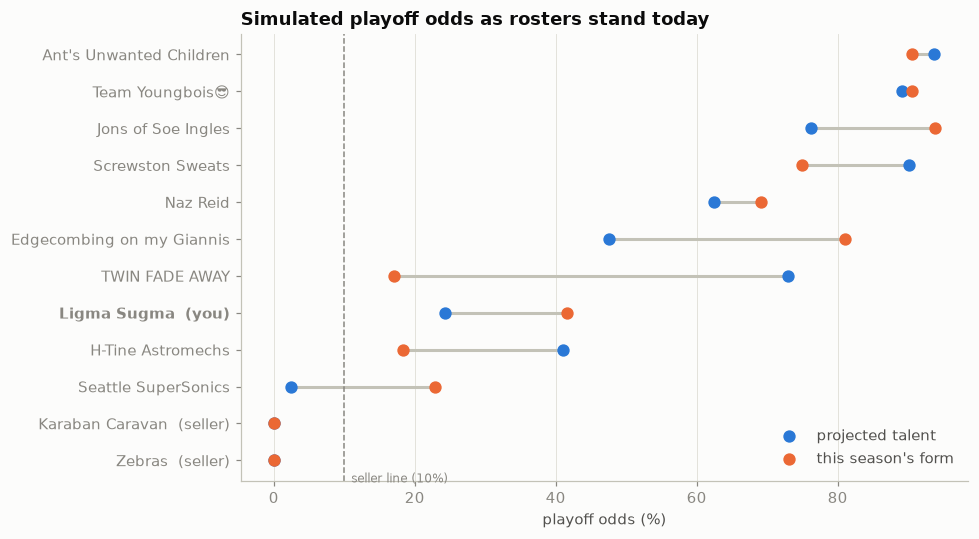

In [3]:
BASE_IN, T0, RES0 = {}, {}, {}
for mode in ('talent', 'form'):
    BASE_IN[mode] = L.inputs(form_only=mode == 'form')
    T0[mode] = {t: L.sim_team(t, ps, SIMS_BASE)[0] for t, ps in BASE_IN[mode].items()}
    RES0[mode] = L.season_results(T0[mode], SIMS_BASE)
FA_POOL = {mode: L.free_agents(form_only=mode == 'form') for mode in ('talent', 'form')}

odds = pd.DataFrame({mode: {t: L.summary(RES0[mode], t)['P(playoffs)'] for t in L.teams} for mode in ('talent', 'form')})
odds['team'] = odds.index.map(L.names); odds['avg'] = odds[['talent', 'form']].mean(1)
odds['role'] = np.where(odds.index == ME, 'you', np.where(odds[['talent', 'form']].max(1) < 0.10, 'seller', 'buyer/bubble'))
odds = odds.sort_values('avg')
ROLE = odds.role.to_dict()

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(odds))
ax.hlines(y, odds[['talent', 'form']].min(1) * 100, odds[['talent', 'form']].max(1) * 100, color=BASE, lw=2)
ax.scatter(odds.talent * 100, y, color=BLUE, s=50, zorder=3, label='projected talent')
ax.scatter(odds.form * 100, y, color=ORANGE, s=50, zorder=3, label="this season's form")
ax.set_yticks(y, [f"{n}  ({r})" if r != 'buyer/bubble' else n for n, r in zip(odds.team, odds.role)])
for lbl, r in zip(ax.get_yticklabels(), odds.role):
    if r == 'you': lbl.set_fontweight('bold')
ax.axvline(10, color=MUTED, ls='--', lw=1); ax.text(11, -0.6, 'seller line (10%)', color=MUTED, fontsize=8)
ax.set_xlabel('playoff odds (%)'); ax.set_title('Simulated playoff odds as rosters stand today'); ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 2. Screen every 1-for-1, 2-for-1, 1-for-2 and 2-for-2 deal

all deals                          201,348
they would plausibly accept         57,452
static gain for me > 0.5             2,361
132 deals go to the simulation


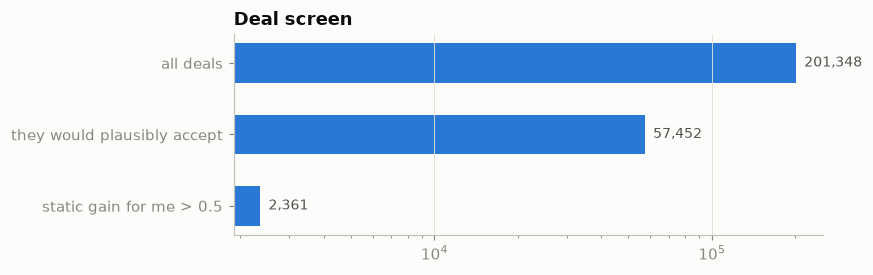

In [4]:
mine = V[V.team_id == ME]
cols = ['val', 'z9', 'dyn9', 'espn']
def combos(df, k_max=2):
    out = []
    for k in range(1, k_max + 1):
        for c in itertools.combinations(df.index, k):
            s = df.loc[list(c), cols].sum()
            out.append({'players': list(c), 'boozer': 'Cameron Boozer' in c, **s.to_dict()})
    return pd.DataFrame(out)
OUT = combos(mine)
rows = []
for tid, g in V[(V.team_id != ME)].groupby('team_id'):
    IN = combos(g)
    X = OUT.merge(IN, how='cross', suffixes=('_out', '_in'))
    X['team_id'] = tid
    rows.append(X)
D = pd.concat(rows, ignore_index=True)
D['boozer'] = D.boozer_out
D['my_gain'] = D.val_in - D.val_out                       # static proxy; the simulation decides
D['their_now'] = D.z9_out - D.z9_in                       # rest-of-season 9-cat value they gain
D['their_dyn'] = D.dyn9_out - D.dyn9_in                   # 5-year value they gain
D['their_espn'] = D.espn_out - D.espn_in                  # what they see on ESPN's rater
D['role'] = D.team_id.map(ROLE)
seller = D.role == 'seller'
accept = np.where(seller, (D.their_dyn >= 0) & (D.their_espn >= -0.5),
                  (D.their_now >= 0) & (D.their_dyn >= -1.0) & (D.their_espn >= -0.5))
steps = [('all deals', np.ones(len(D), bool)), ('they would plausibly accept', accept),
         ('static gain for me > 0.5', accept & (D.my_gain > 0.5))]
for n, s in steps: print(f'{n:32s} {s.sum():>9,}')
C = D[steps[-1][1]].copy()
# per team: best PER_TEAM by static gain, half with Boozer allowed and half without, so both show up
short = pd.concat([C[C.boozer].sort_values('my_gain', ascending=False).groupby('team_id').head(PER_TEAM // 3),
                   C[~C.boozer].sort_values('my_gain', ascending=False).groupby('team_id').head(PER_TEAM - PER_TEAM // 3)])
short = short.drop_duplicates(subset=['team_id', 'my_gain', 'val_out']).reset_index(drop=True)
short['team'] = short.team_id.map(L.names)
short['deal'] = short.players_out.str.join(' + ') + '  ->  ' + short.players_in.str.join(' + ')
print(len(short), 'deals go to the simulation')

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh([s[0] for s in steps][::-1], [s[1].sum() for s in steps][::-1], color=BLUE, height=0.55)
for i, s in enumerate(steps[::-1]): ax.text(s[1].sum(), i, f'  {s[1].sum():,}', va='center', color=INK2, fontsize=9)
ax.set_xscale('log'); ax.set_title('Deal screen'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [5]:
RES_CACHE = {}
def player_in(name, mode, mine_targets):
    return L.player(L.rosters[L.rosters.player_name == name].iloc[0], mode == 'form', mine_targets)

def simulate(give, get, partner, mode, sims):
    base = BASE_IN[mode]
    me = {k: v for k, v in base[ME].items() if k not in give}
    me.update({n: player_in(n, mode, True) for n in get})
    pt = {k: v for k, v in base[partner].items() if k not in get}
    pt.update({n: player_in(n, mode, False) for n in give})
    me = {k: v for k, v in me.items() if v}; pt = {k: v for k, v in pt.items() if v}
    drop = None
    while len(me) > len(base[ME]):
        drop = min((p for p in me.values() if p['name'] not in get), key=lambda p: p['val'])['name']; me.pop(drop)
    while len(pt) > len(base[partner]):
        d = min((p for p in pt.values() if p['name'] not in give), key=lambda p: p['val'])['name']; pt.pop(d)
    fas = iter(p for p in FA_POOL[mode] if p['name'] not in get and p['name'] != drop)
    for t, ros in ((ME, me), (partner, pt)):
        while len(ros) < len(base[t]):
            p = next(fas); ros[p['name']] = p if t != ME else {**p, 'val': p['val_targets']}
    T = {t: v[:sims] for t, v in T0[mode].items()}
    T[ME] = L.sim_team(ME, me, sims)[0]; T[partner] = L.sim_team(partner, pt, sims)[0]
    res = L.season_results(T, sims)
    if (mode, sims) not in RES_CACHE:
        RES_CACHE[(mode, sims)] = L.season_results({t: v[:sims] for t, v in T0[mode].items()}, sims)
    res0 = RES_CACHE[(mode, sims)]
    my, my0 = L.my_summary(res), L.my_summary(res0)
    return {'drop': drop, 'my_dp': my['P(playoffs)'] - my0['P(playoffs)'], 'my_dtitle': my['P(title)'] - my0['P(title)'],
            'their_dp': L.summary(res, partner)['P(playoffs)'] - L.summary(res0, partner)['P(playoffs)'],
            **{f'd_{c}': my[c] - my0[c] for c in ['PTS', 'REB', 'AST', 'STL', 'BLK', 'FG3M', 'TOV', 'FG%', 'FT%', 'exp_cats_won']}}

t0 = time.time(); out = []
for _, d in short.iterrows():
    row = {'team': d.team, 'role': d.role, 'deal': d.deal, 'boozer': d.boozer, 'give': d.players_out, 'get': d.players_in,
           'team_id': d.team_id, 'their_dyn': d.their_dyn, 'their_espn': d.their_espn, 'their_now': d.their_now}
    for mode in ('talent', 'form'):
        row.update({f'{k}_{mode}': v for k, v in simulate(d.players_out, d.players_in, d.team_id, mode, SIMS_SCREEN).items()})
    out.append(row)
S = pd.DataFrame(out)
S['my_dp'] = S[['my_dp_talent', 'my_dp_form']].mean(1); S['my_dp_min'] = S[['my_dp_talent', 'my_dp_form']].min(1)
S['their_dp'] = S[['their_dp_talent', 'their_dp_form']].mean(1)
S['accept'] = (S.role == 'seller') | (S[['their_dp_talent', 'their_dp_form']].min(1) >= -0.02)
print(f'screened {len(S)} deals in {time.time() - t0:.0f}s')
display(S.sort_values('my_dp', ascending=False)[['team', 'role', 'deal', 'my_dp_talent', 'my_dp_form', 'their_dp', 'their_dyn', 'their_espn', 'accept']].head(20).round(3))

screened 132 deals in 343s


,team,role,deal,my_dp_talent,my_dp_form,their_dp,their_dyn,their_espn,accept
26,Screwston Sweats,buyer/bubble,Myles Turner + Cameron Boozer -> Jalen Brunson + Bobby Portis,0.137,0.093,-0.058,5.958,2.399,False
42,H-Tine Astromechs,buyer/bubble,Myles Turner + Cameron Boozer -> Toumani Camara + Collin Gillespie,0.007,0.137,-0.038,5.573,3.719,False
18,Screwston Sweats,buyer/bubble,Myles Turner + Cameron Boozer -> AJ Dybantsa + Jayson Tatum,0.027,0.090,-0.043,-0.563,1.882,False
57,Karaban Caravan,seller,Naji Marshall + Moritz Wagner -> DeMar DeRozan,0.127,-0.010,0.000,0.252,4.285,True
20,Screwston Sweats,buyer/bubble,Myles Turner + Cameron Boozer -> Jalen Brunson + Jaime Jaquez Jr.,0.043,0.063,-0.077,4.432,-0.423,False
28,Edgecombing on my Giannis,buyer/bubble,Cameron Boozer -> Draymond Green + Damian Lillard,0.087,0.003,-0.038,3.967,0.006,False
4,Zebras,seller,Cameron Boozer + Moritz Wagner -> Payton Pritchard,0.110,-0.020,0.000,3.107,3.929,True
38,Ant's Unwanted Children,buyer/bubble,Myles Turner + Cameron Boozer -> Devin Vassell + Brandin Podziemski,-0.023,0.110,-0.055,-0.617,0.706,False
43,H-Tine Astromechs,buyer/bubble,Myles Turner + Cameron Boozer -> Toumani Camara,-0.023,0.093,0.087,10.009,5.135,True
14,Seattle SuperSonics,buyer/bubble,Myles Turner + Cameron Boozer -> Keaton Wagler + Paul George,-0.043,0.110,-0.045,5.160,0.654,False


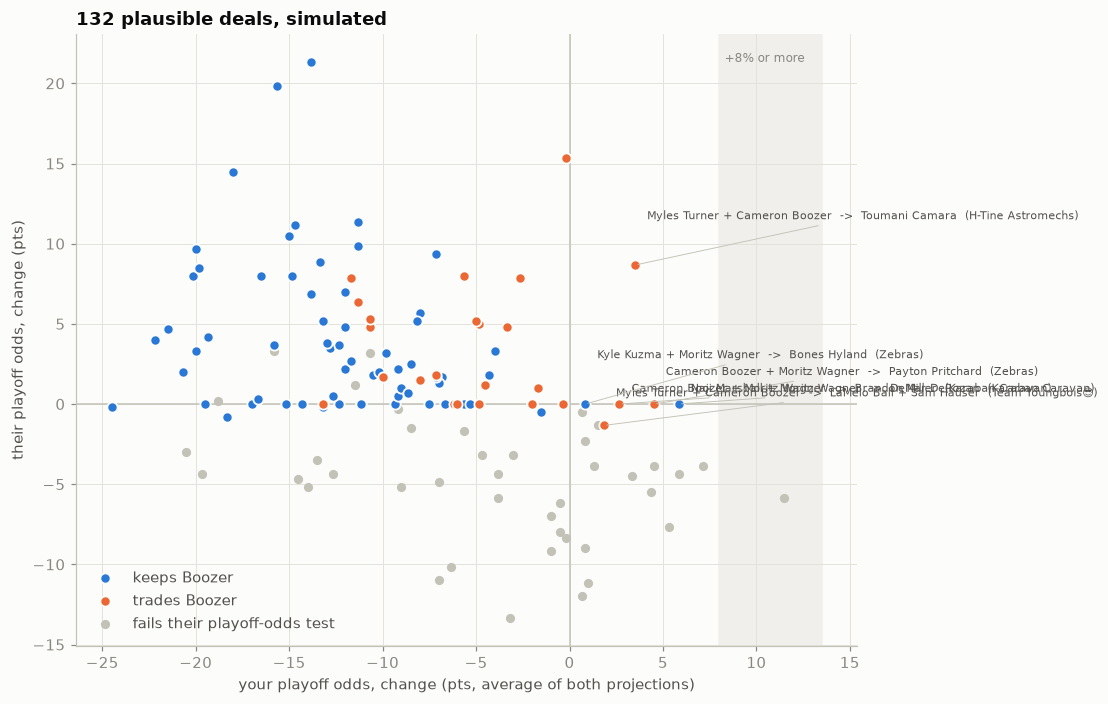

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axvline(0, color=BASE, lw=1); ax.axhline(0, color=BASE, lw=1)
ax.axvspan(SIGNIFICANT * 100, max(S.my_dp.max() * 100 + 2, SIGNIFICANT * 100 + 2), color=NEUTRAL, zorder=0)
for b, col, lab in ((False, BLUE, 'keeps Boozer'), (True, ORANGE, 'trades Boozer')):
    d = S[(S.boozer == b) & S.accept]
    ax.scatter(d.my_dp * 100, d.their_dp * 100, color=col, s=45, edgecolor=SURF, linewidth=1.2, zorder=3, label=lab)
d = S[~S.accept]
ax.scatter(d.my_dp * 100, d.their_dp * 100, color=BASE, s=25, zorder=2, label='fails their playoff-odds test')
for k, (_, r) in enumerate(S[S.accept].nlargest(6, 'my_dp').iterrows()):
    ax.annotate(f"{r.deal}  ({r.team})", (r.my_dp * 100, r.their_dp * 100), xytext=(8, 8 + 11 * (k % 3)),
                textcoords='offset points', fontsize=7.5, color=INK2, arrowprops=dict(arrowstyle='-', color=BASE, lw=0.6))
ax.text(SIGNIFICANT * 100 + 0.3, ax.get_ylim()[1] * 0.95, f'+{SIGNIFICANT:.0%} or more', color=MUTED, fontsize=8, va='top')
ax.set_xlabel('your playoff odds, change (pts, average of both projections)'); ax.set_ylabel('their playoff odds, change (pts)')
ax.set_title(f'{len(S)} plausible deals, simulated'); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

## 3. Validate the best deals with 1,000 seasons

In [7]:
top = pd.concat([S[S.accept & ~S.boozer].nlargest(4, 'my_dp'), S[S.accept & S.boozer].nlargest(2, 'my_dp')])
final = []
for _, d in top.iterrows():
    row = {'team': d.team, 'role': d.role, 'deal': d.deal, 'boozer': d.boozer, 'their_dyn': d.their_dyn, 'their_espn': d.their_espn}
    for mode in ('talent', 'form'):
        row.update({f'{k}_{mode}': v for k, v in simulate(d['give'], d['get'], d.team_id, mode, SIMS_FINAL).items()})
    final.append(row)
F = pd.DataFrame(final)
F['my_dp'] = F[['my_dp_talent', 'my_dp_form']].mean(1)
F['their_ok'] = (F.role == 'seller') | (F[['their_dp_talent', 'their_dp_form']].min(1) >= -0.02)
F = F.sort_values('my_dp', ascending=False)
base_p = {mode: L.my_summary(RES0[mode])['P(playoffs)'] for mode in ('talent', 'form')}
print('your playoff odds as is:', {k: round(v, 3) for k, v in base_p.items()})
display(F[['team', 'role', 'deal', 'drop_talent', 'my_dp_talent', 'my_dp_form', 'my_dtitle_talent',
           'their_dp_talent', 'their_dp_form', 'their_dyn', 'their_espn', 'their_ok']].round(3))

your playoff odds as is: {'talent': np.float64(0.243), 'form': np.float64(0.416)}


,team,role,deal,drop_talent,my_dp_talent,my_dp_form,my_dtitle_talent,their_dp_talent,their_dp_form,their_dyn,their_espn,their_ok
5,H-Tine Astromechs,buyer/bubble,Myles Turner + Cameron Boozer -> Toumani Camara,None,0.036,0.072,0.007,0.077,0.037,10.009,5.135,True
0,Karaban Caravan,seller,Naji Marshall + Moritz Wagner -> DeMar DeRozan,None,0.109,-0.012,0.013,0.000,0.000,0.252,4.285,True
4,Zebras,seller,Cameron Boozer + Moritz Wagner -> Payton Pritchard,None,0.096,-0.026,0.016,0.000,0.000,3.107,3.929,True
1,Zebras,seller,Kyle Kuzma + Moritz Wagner -> Bones Hyland,None,0.035,-0.007,0.004,0.000,0.000,0.000,0.124,True
3,Karaban Caravan,seller,Ajay Mitchell + Tre Jones -> Darius Acuff Jr.,None,0.016,-0.016,-0.005,0.000,0.000,0.623,2.080,True
2,Screwston Sweats,buyer/bubble,Pascal Siakam + Myles Turner -> Jalen Brunson + Bobby Portis,None,-0.009,-0.001,0.001,0.008,-0.014,0.636,2.445,True


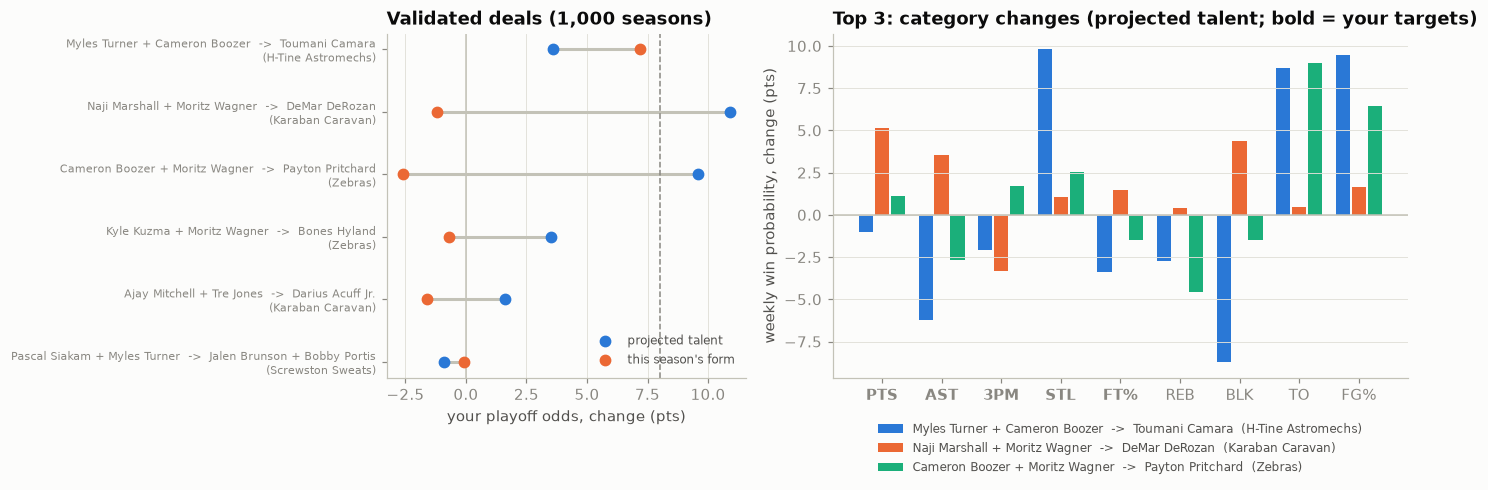

In [8]:
cats = ['PTS', 'AST', 'FG3M', 'STL', 'FT%', 'REB', 'BLK', 'TOV', 'FG%']
lab = {'FG3M': '3PM', 'TOV': 'TO'}
show = F.head(3)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.6]})
ax = axs[0]
yy = np.arange(len(F))[::-1]
ax.hlines(yy, F.my_dp_form * 100, F.my_dp_talent * 100, color=BASE, lw=2)
ax.scatter(F.my_dp_talent * 100, yy, color=BLUE, s=45, zorder=3, label='projected talent')
ax.scatter(F.my_dp_form * 100, yy, color=ORANGE, s=45, zorder=3, label="this season's form")
ax.set_yticks(yy, [f"{d}\n({t})" for d, t in zip(F.deal, F.team)], fontsize=7.5)
ax.axvline(0, color=BASE, lw=1); ax.axvline(SIGNIFICANT * 100, color=MUTED, ls='--', lw=1)
ax.set_xlabel('your playoff odds, change (pts)'); ax.set_title('Validated deals (1,000 seasons)'); ax.legend(loc='lower right', fontsize=8)
ax.grid(axis='y', visible=False)
ax = axs[1]
x = np.arange(len(cats)); w = 0.8 / len(show)
for i, (_, r) in enumerate(show.iterrows()):
    ax.bar(x + i * w - 0.4 + w / 2, [r[f'd_{c}_talent'] * 100 for c in cats], w * 0.9, color=[BLUE, ORANGE, AQUA][i],
           label=f"{r.deal}  ({r.team})")
ax.axhline(0, color=BASE, lw=1); ax.set_xticks(x, [lab.get(c, c) for c in cats])
for t in ax.get_xticklabels():
    if t.get_text() in ('PTS', 'AST', '3PM', 'STL', 'FT%'): t.set_fontweight('bold')
ax.set_ylabel('weekly win probability, change (pts)'); ax.grid(axis='x', visible=False)
ax.set_title('Top 3: category changes (projected talent; bold = your targets)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=8)
plt.tight_layout(); plt.show()

## 4. Conclusions

_Written after the run._